## Data Labeling

In [1]:
import os
import numpy as np
import pandas as pd 
import seaborn as sn 
import matplotlib.pyplot as plt 

In [18]:
!git clone https://github.com/https-deeplearning-ai/MLEP-public.git

Cloning into 'MLEP-public'...


## Load dataset function

In [9]:
def load_labeled_spam_dataset():
    """Load the 5 csv datasets in the dataset path"""

    base_path = "./data/youtube+spam+collection"

    csv_files = [os.path.join(base_path, csv) for csv in os.listdir(base_path)]

    dfs = [pd.read_csv(filename) for filename in csv_files]

    df = pd.concat(dfs)

    df = df.rename(columns={"CONTENT": "text", "CLASS": "label"})

    df = df.sample(frac=1, random_state=423)

    return df.reset_index()



## Inspect the final dataset

In [10]:
df_labeled = load_labeled_spam_dataset()
df_labeled.head(5)

,index,COMMENT_ID,AUTHOR,DATE,text,label
0,349,z120e5uautvcuper304ccf4bjrjugdpbwrc0k,moaz adnan,2015-06-05T20:01:23,who is going to reach the billion first : katy...,0
1,255,z12ts1xbpzv4sfrsd23rfbjourjgcj5mo,Gema LR,2014-11-08T03:26:51,With the korean girl more slut and bitch : Hyu...,0
2,49,z13df5jp4umzg3jhw04chniaxlviirc4hqs0k,Tominke Urbančok,2015-05-26T12:29:11.663000,Very Nice !!!<br />Yeah Fucking.﻿,0
3,110,z13xxf3qlq2bxpm1o22zidpqbn2tfpcjr04,Connor Mire,2015-05-21T20:46:54.704000,This Song is AWESOME!!!!﻿,0
4,252,z12tzpcjazigvrodo22dubixisqhfxtuo,twe enyss,2015-05-23T16:41:29.823000,"I love this-the talents of eminem and Skylar,w...",0


## Inspect data balanced

Value counts for each class:
 label
1    1005
0     951
Name: count, dtype: int64


<Axes: title={'center': 'Proportion of each class'}, ylabel='count'>

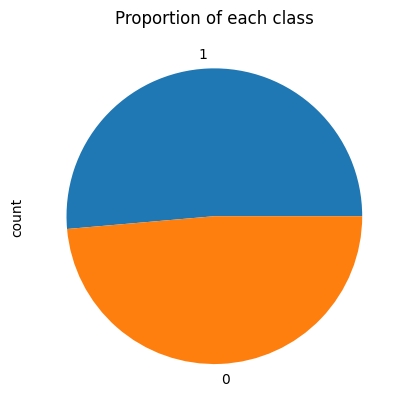

In [17]:
print(f'Value counts for each class:\n {df_labeled.label.value_counts()}')
df_labeled.label.value_counts().plot.pie(y="label", title="Proportion of each class")

## Cleaning the dataset

In [ ]:
df_labeled = df_labeled.drop(["index", "COMMENT_ID", "AUTHOR", "DATE"], axis=1)

In [21]:
df_labeled.head(5)

,text,label
0,who is going to reach the billion first : katy...,0
1,With the korean girl more slut and bitch : Hyu...,0
2,Very Nice !!!<br />Yeah Fucking.﻿,0
3,This Song is AWESOME!!!!﻿,0
4,"I love this-the talents of eminem and Skylar,w...",0


##### Now are dataset only include relevant information

## Splitting the dataset

In [22]:
from sklearn.model_selection import train_test_split

In [ ]:
X = df_labeled.drop(columns="label")
y = df_labeled["label"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, train_size=0.8, stratify=y)

There are 1564 comments for training and 1564 for testing


In [27]:
print(f'There are {X_train.shape[0]} comments for training and {X_test.shape[0]} for testing')

There are 1564 comments for training and 392 for testing


#### Check if the stratification worked as expected

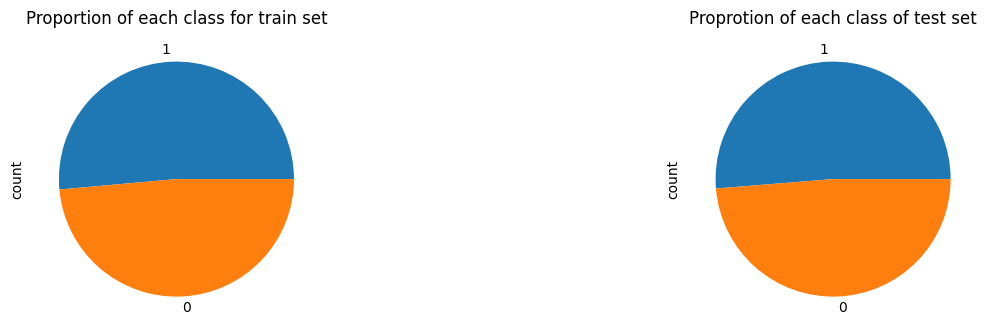

In [42]:
plt.subplot(1, 3, 1)
y_train.value_counts().plot.pie(y='label', title='Proportion of each class for train set', figsize=(10,6))
plt.subplot(1, 3, 3)
y_test.value_counts().plot.pie(y="label", title="Proprotion of each class of test set")
plt.tight_layout()
plt.show()

## Data Labeling

#### Establishing oerformance lower and upper bounds for reference + Text Encoding with CountVectorizer

##### To properly compare different label strategies, we need to establish a baseline for model accuracy. In this case, we will establish both a lower and an upper bound to compare different strategies against.

CountVectorizer is a handly tool included in sklearn ecosystem to encode text-based data

In [43]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(ngram_range=(1, 5))

#### Now that the text encoding is defined, we will select the Multinomial Naive Bayes classifier. This model is well suited for text classification and is fairly quick to train.
We will define a function to handle model fitting and print out the accuracy on the test data

In [52]:
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import MultinomialNB

def calculate_accuracy(X_tr, y_tr, X_te = X_test, y_te = y_test, clf=MultinomialNB(), vectorizer=vectorizer):

    X_train_vect = vectorizer.fit_transform(X_tr.text.tolist())

    clf.fit(X_train_vect, y_tr)

    X_test_vect = vectorizer.transform(X_te.text.tolist())

    preds = clf.predict(X_test_vect)

    acc = accuracy_score(preds, y_te)

    return acc

#### Next, create a dictionary to store the accuracy of each labeling method

In [67]:
# Empty dictionary
accs = dict()

### RANDOM LABELING

In [57]:
rnd_labels = np.random.randint(0,2, X_train.shape[0])
acc = calculate_accuracy(X_train, rnd_labels)
acc

0.49744897959183676

In [68]:
rnd_accs = []

for _ in range(10):
    rnd_labels = np.random.randint(0, 2, X_train.shape[0])
    acc = calculate_accuracy(X_train, rnd_labels)
    rnd_accs.append(acc)

avg_acc = sum(rnd_accs)/len(rnd_accs)

accs["random-labeling"]=avg_acc

avg_acc

0.5204081632653061

In [64]:
print(f'The average accuracy for random labels is {avg_acc*100:.2f}%')

The average accuracy for random labels is 47.73%


### GROUND TRUTH VALUES

In [69]:
true_acc = calculate_accuracy(X_train, y_train)
accs["ground-truth"]=true_acc

print(f'The ground truth label accuracy is {true_acc}')

The ground truth label accuracy is 0.9030612244897959


#### Ground truth labeling produced a boost in accuracy. This result is expected, as the classifier can now properly identify patterns in the training data echich were lacking with randomly generated labels

### AUTOMATIC LABELING - TRYING OUT DIFFERENT LABEL STRATEGIES

#### Suppose we don´t have access to the true labels for this dataste - a common situation in ML. It´s natural to assume that there are patterns in the data that can provide clues about the correct labels. These patterns are dependent on the kind of data we are working with; to even hypothesize which patterns exist usually requires great domain knowledge.

#### For this particular dataste, we can likely come up with some useful rules that might help distinguish a spam Youtube comment from non-spam. 

#### `SPAM` is represented by 1 
#### `NOT SPAM` is represented by 0
#### `NO_LABEL` by -1'
We will use the `NO_LABEL` keyword when the rules we come up with don't apply to some data points. In those cases, it is better to avoid giving a label rather than guessing, which we already saw yields poor results.

## First iteration - Define some rules

#### For this first iteration, we will create three rules based on intuition about common patterns that appear in spam comments.

#### - `free` - promoting free stuff
#### - `subs` - ask users to suscribe
#### - `http` - include links

In [74]:
def labeling_rules_1(x):
    x = x.lower()

    rules = [
        "free" in x,
        "subs" in x,
        "http" in x
    ]

    if any(rules):
        return 1

    return -1

In [76]:
labels = [labeling_rules_1(label) for label in X_train.text]
labels = np.asarray(labels)
labels

array([ 1, -1, -1, ..., -1,  1, -1], shape=(1564,))